In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_classification, load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.base import BaseEstimator, ClassifierMixin

# Cargar / crear los datasets según especificaciones
X_moons, y_moons = make_moons(n_samples=1000, noise=0.15, random_state=0)
X_classification, y_classification = make_classification(
    n_samples=1000, n_features=3, n_informative=3, n_redundant=0,
    n_repeated=0, n_classes=3, n_clusters_per_class=1, random_state=0
)
X_iris, y_iris = load_iris(return_X_y=True)
X_digits, y_digits = load_digits(return_X_y=True)

problemas = {
    "make_moons": (X_moons, y_moons),
    "make_classification": (X_classification, y_classification),
    "iris": (X_iris, y_iris),
    "digits": (X_digits, y_digits),
}

In [2]:
class MinimumDistanceClassifier(BaseEstimator, ClassifierMixin):
    """Clasificador de mínima distancia euclidiana a los centroides de clase."""
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.centroids_ = {}
        for cls in self.classes_:
            self.centroids_[cls] = np.mean(X[y == cls], axis=0)
        return self
    
    def predict(self, X):
        preds = []
        for x in X:
            dists = {cls: np.linalg.norm(x - centroid) for cls, centroid in self.centroids_.items()}
            preds.append(min(dists, key=dists.get))
        return np.array(preds)


class PocketPerceptron(BaseEstimator, ClassifierMixin):
    """Algoritmo del bolsillo (Pocket) para clasificación binaria."""
    def __init__(self, alpha=0.25, max_iter=2500):
        self.alpha = alpha
        self.max_iter = max_iter
    
    def fit(self, X, y):
        # Convertir etiquetas a -1 y +1 (asumimos y en {0,1})
        y_ = np.where(y == 0, -1, 1)
        n_samples, n_features = X.shape
        w = np.zeros(n_features + 1)  # [bias, pesos]
        X_ext = np.c_[np.ones(n_samples), X]  # añadir columna de unos para el bias
        best_w = w.copy()
        best_acc = 0.0
        
        for _ in range(self.max_iter):
            # Mezclar datos en cada época
            idx = np.random.permutation(n_samples)
            X_shuf = X_ext[idx]
            y_shuf = y_[idx]
            for xi, yi in zip(X_shuf, y_shuf):
                if np.sign(np.dot(w, xi)) * yi <= 0:
                    w = w + self.alpha * yi * xi
                    # Evaluar en todo el conjunto de entrenamiento
                    y_pred = np.sign(np.dot(X_ext, w))
                    acc = np.mean(y_pred == y_)
                    if acc > best_acc:
                        best_acc = acc
                        best_w = w.copy()
        self.w_ = best_w
        self.classes_ = np.array([0, 1])
        return self
    
    def predict(self, X):
        X_ext = np.c_[np.ones(X.shape[0]), X]
        y_pred = np.sign(np.dot(X_ext, self.w_))
        return np.where(y_pred == -1, 0, 1)

In [4]:
# Almacenar resultados: lista de diccionarios
resultados = []
n_ejecuciones = 35

for nombre_problema, (X, y) in problemas.items():
    print(f"Procesando {nombre_problema}...")
    
    # Determinar lista de clasificadores según el problema
    clasificadores = []
    
    # Todos los problemas aceptan regresión logística, KNN, mínima distancia y Bayes
    # IMPORTANTE: se elimina random_state de LogisticRegression
    clasificadores.append(("Regresión Logística", 
                           LogisticRegression(max_iter=2500, solver='saga', multi_class='multinomial')))
    clasificadores.append(("Mínima Distancia", MinimumDistanceClassifier()))
    clasificadores.append(("KNN-1", KNeighborsClassifier(n_neighbors=1)))
    clasificadores.append(("KNN-3", KNeighborsClassifier(n_neighbors=3)))
    clasificadores.append(("KNN-5", KNeighborsClassifier(n_neighbors=5)))
    clasificadores.append(("Bayes Ingenuo", GaussianNB()))
    
    # Perceptrón y Pocket solo para problemas binarios (make_moons)
    # Se elimina random_state del Perceptrón
    if nombre_problema == "make_moons":
        clasificadores.append(("Perceptrón", Perceptron(max_iter=2500, eta0=0.25)))
        clasificadores.append(("Pocket", PocketPerceptron(alpha=0.25, max_iter=2500)))
    
    # Bucle de ejecuciones
    for ejecucion in range(n_ejecuciones):
        # División sin random_state: cada ejecución tendrá una partición aleatoria distinta
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            train_size=0.70,
            test_size=0.30,
            stratify=y
        )
        
        for nombre_algo, modelo in clasificadores:
            # Entrenar
            modelo.fit(X_train, y_train)
            # Predicciones
            y_pred_train = modelo.predict(X_train)
            y_pred_test = modelo.predict(X_test)
            # Exactitudes
            acc_train = accuracy_score(y_train, y_pred_train)
            acc_test = accuracy_score(y_test, y_pred_test)
            
            # Guardar registro
            resultados.append({
                "Problema": nombre_problema,
                "Algoritmo": nombre_algo,
                "Ejecución": ejecucion,
                "Exactitud Entrenamiento": acc_train,
                "Exactitud Prueba": acc_test
            })

print("Experimento finalizado.")

Procesando make_moons...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1262: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1262: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1262: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed i

Procesando make_classification...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Pytho

Procesando iris...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Pytho

Procesando digits...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Pytho

Experimento finalizado.


In [5]:
df = pd.DataFrame(resultados)
# Mostrar las primeras filas para verificar
df.head()

,Problema,Algoritmo,Ejecución,Exactitud Entrenamiento,Exactitud Prueba
0,make_moons,Regresión Logística,0,0.865714,0.873333
1,make_moons,Mínima Distancia,0,0.785714,0.813333
2,make_moons,KNN-1,0,1.000000,0.973333
3,make_moons,KNN-3,0,0.995714,0.973333
4,make_moons,KNN-5,0,0.995714,0.973333


In [6]:
# Agrupar por Problema y Algoritmo, calcular media y desviación estándar
resumen = df.groupby(["Problema", "Algoritmo"]).agg(
    Media_Entrenamiento=("Exactitud Entrenamiento", "mean"),
    Std_Entrenamiento=("Exactitud Entrenamiento", "std"),
    Media_Prueba=("Exactitud Prueba", "mean"),
    Std_Prueba=("Exactitud Prueba", "std")
).reset_index()

# Redondear a 4 decimales
resumen.iloc[:, 2:] = resumen.iloc[:, 2:].round(4)
resumen

,Problema,Algoritmo,Media_Entrenamiento,Std_Entrenamiento,Media_Prueba,Std_Prueba
0,digits,Bayes Ingenuo,0.8593,0.0213,0.8388,0.0234
1,digits,KNN-1,1.0000,0.0000,0.9858,0.0048
2,digits,KNN-3,0.9933,0.0016,0.9863,0.0045
3,digits,KNN-5,0.9899,0.0016,0.9849,0.0051
4,digits,Mínima Distancia,0.9063,0.0044,0.9007,0.0114
5,digits,Regresión Logística,1.0000,0.0000,0.9624,0.0084
6,iris,Bayes Ingenuo,0.9543,0.0105,0.9594,0.0244
7,iris,KNN-1,1.0000,0.0000,0.9625,0.0240
8,iris,KNN-3,0.9641,0.0133,0.9657,0.0197
9,iris,KNN-5,0.9717,0.0110,0.9632,0.0258


In [7]:
for problema in resumen["Problema"].unique():
    print(f"\n===== Problema: {problema} =====")
    tabla = resumen[resumen["Problema"] == problema].drop(columns="Problema").set_index("Algoritmo")
    display(tabla)
    
    if problema != "make_moons":
        print("Nota: Perceptrón y Pocket no aplican por ser clasificadores binarios.")
    else:
        print("Se aplicaron todos los algoritmos.")


===== Problema: digits =====


,Media_Entrenamiento,Std_Entrenamiento,Media_Prueba,Std_Prueba
Algoritmo,,,,
Bayes Ingenuo,0.8593,0.0213,0.8388,0.0234
KNN-1,1.0000,0.0000,0.9858,0.0048
KNN-3,0.9933,0.0016,0.9863,0.0045
KNN-5,0.9899,0.0016,0.9849,0.0051
Mínima Distancia,0.9063,0.0044,0.9007,0.0114
Regresión Logística,1.0000,0.0000,0.9624,0.0084


Nota: Perceptrón y Pocket no aplican por ser clasificadores binarios.

===== Problema: iris =====


,Media_Entrenamiento,Std_Entrenamiento,Media_Prueba,Std_Prueba
Algoritmo,,,,
Bayes Ingenuo,0.9543,0.0105,0.9594,0.0244
KNN-1,1.0000,0.0000,0.9625,0.0240
KNN-3,0.9641,0.0133,0.9657,0.0197
KNN-5,0.9717,0.0110,0.9632,0.0258
Mínima Distancia,0.9271,0.0144,0.9225,0.0379
Regresión Logística,0.9774,0.0098,0.9708,0.0200


Nota: Perceptrón y Pocket no aplican por ser clasificadores binarios.

===== Problema: make_classification =====


,Media_Entrenamiento,Std_Entrenamiento,Media_Prueba,Std_Prueba
Algoritmo,,,,
Bayes Ingenuo,0.9073,0.0051,0.9097,0.0159
KNN-1,1.0000,0.0000,0.9819,0.0073
KNN-3,0.9901,0.0025,0.9862,0.0062
KNN-5,0.9878,0.0023,0.9854,0.0065
Mínima Distancia,0.8945,0.0058,0.8959,0.0168
Regresión Logística,0.9819,0.0043,0.9814,0.0073


Nota: Perceptrón y Pocket no aplican por ser clasificadores binarios.

===== Problema: make_moons =====


,Media_Entrenamiento,Std_Entrenamiento,Media_Prueba,Std_Prueba
Algoritmo,,,,
Bayes Ingenuo,0.8688,0.0066,0.8684,0.0156
KNN-1,1.0000,0.0000,0.9777,0.0065
KNN-3,0.9912,0.0031,0.9840,0.0069
KNN-5,0.9902,0.0031,0.9844,0.0068
Mínima Distancia,0.7915,0.0086,0.7915,0.0207
Perceptrón,0.8351,0.0413,0.8325,0.0427
Pocket,0.8804,0.0058,0.8640,0.0141
Regresión Logística,0.8682,0.0060,0.8676,0.0142


Se aplicaron todos los algoritmos.


/var/folders/6_/lpc813z94b5fffxx1g7sc9yc0000gn/T/ipykernel_73828/1750180361.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=orden, patch_artist=True)


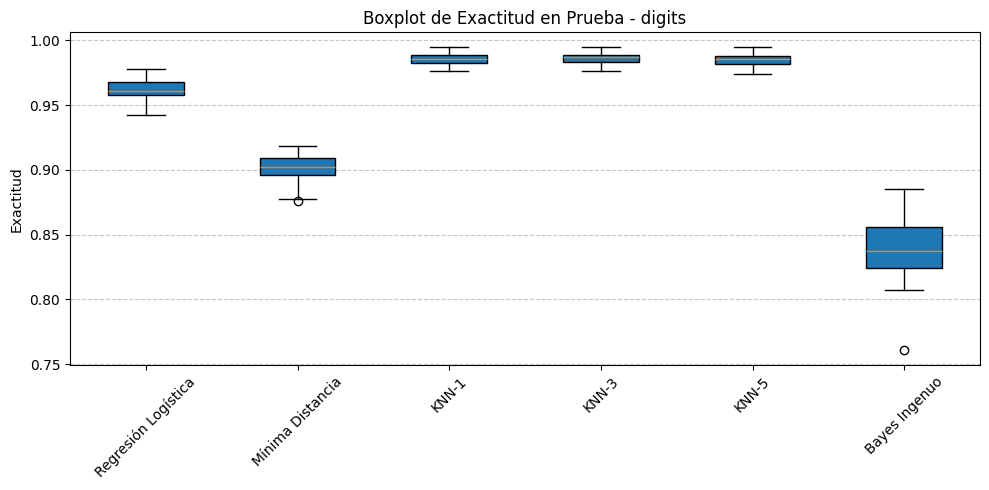

/var/folders/6_/lpc813z94b5fffxx1g7sc9yc0000gn/T/ipykernel_73828/1750180361.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=orden, patch_artist=True)


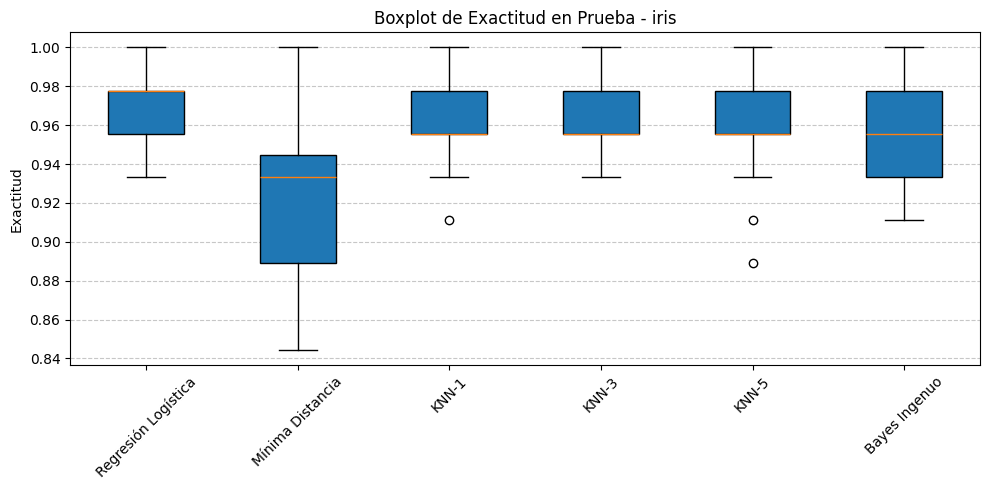

/var/folders/6_/lpc813z94b5fffxx1g7sc9yc0000gn/T/ipykernel_73828/1750180361.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=orden, patch_artist=True)


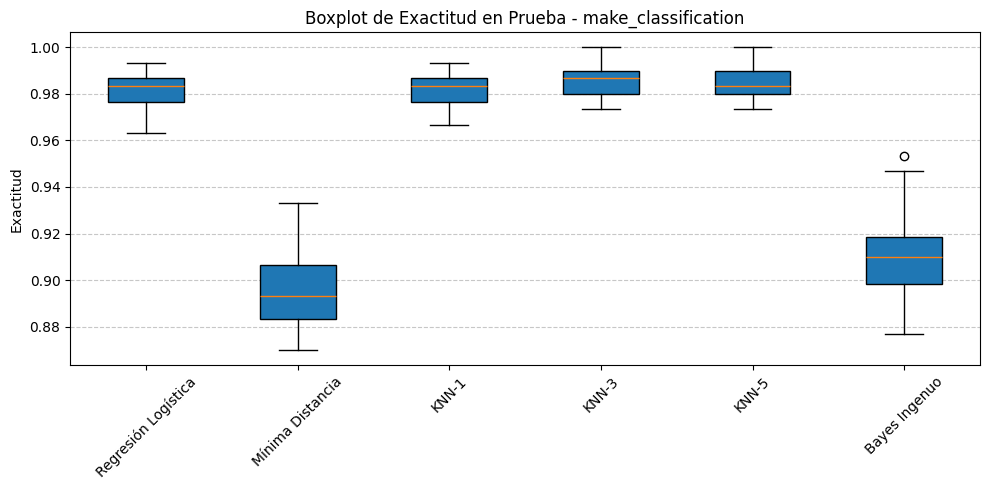

/var/folders/6_/lpc813z94b5fffxx1g7sc9yc0000gn/T/ipykernel_73828/1750180361.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=orden, patch_artist=True)


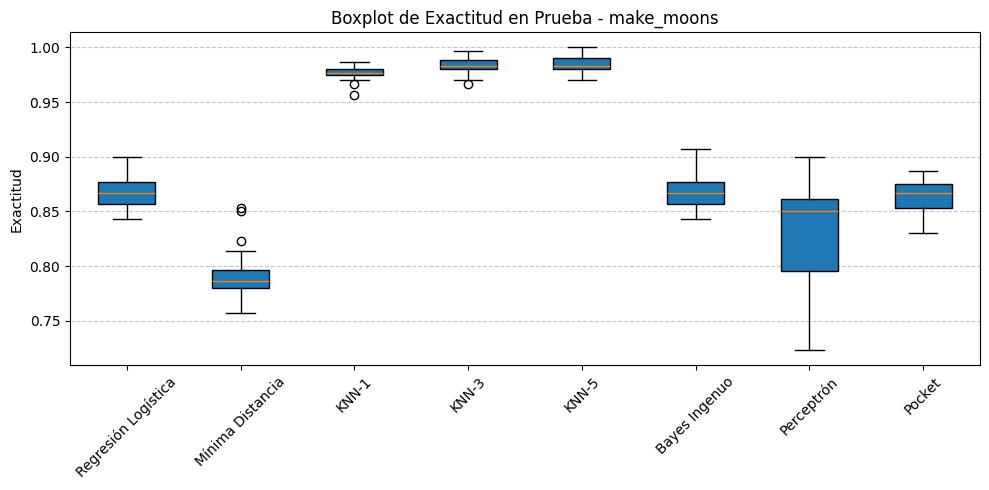

In [8]:
for problema in resumen["Problema"].unique():
    plt.figure(figsize=(10, 5))
    sub_df = df[df["Problema"] == problema]
    # Ordenar algoritmos para que aparezcan en un orden fijo
    orden = ["Regresión Logística", "Mínima Distancia", "KNN-1", "KNN-3", "KNN-5", "Bayes Ingenuo"]
    if problema == "make_moons":
        orden += ["Perceptrón", "Pocket"]
    # Asegurar que solo aparezcan los que realmente se usaron
    orden = [algo for algo in orden if algo in sub_df["Algoritmo"].unique()]
    
    data = [sub_df[sub_df["Algoritmo"] == algo]["Exactitud Prueba"].values for algo in orden]
    plt.boxplot(data, labels=orden, patch_artist=True)
    plt.title(f"Boxplot de Exactitud en Prueba - {problema}")
    plt.ylabel("Exactitud")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

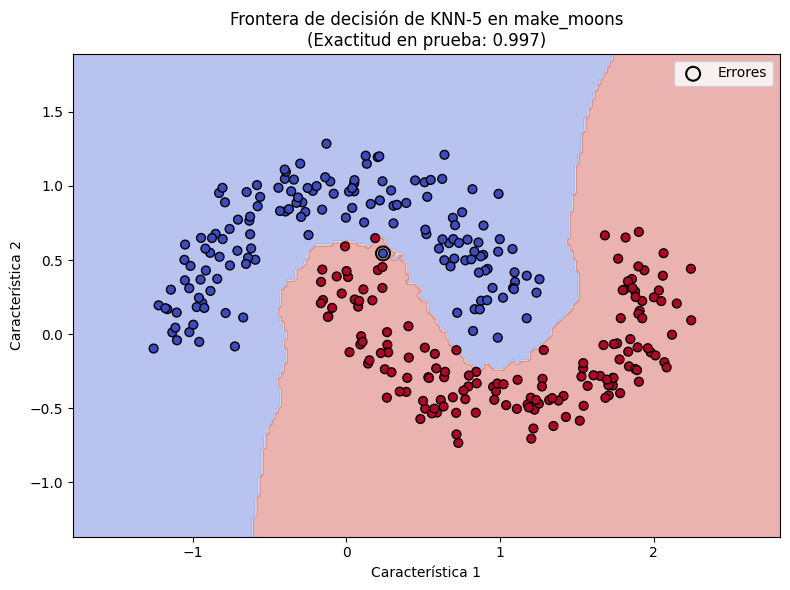

In [9]:
# Celda: Visualización make_moons con KNN-5
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=1000, noise=0.15, random_state=0)
# Usamos una partición fija solo para generar la figura (no afecta al experimento)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, stratify=y, random_state=1000)

modelo = KNeighborsClassifier(n_neighbors=5)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Crear malla
h = 0.02
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap='coolwarm')
# Dibujar puntos de prueba
scatter = plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolor='k', s=40)
# Marcar errores
errores = y_pred != y_test
plt.scatter(X_test[errores, 0], X_test[errores, 1], facecolors='none', edgecolors='black', 
            s=100, linewidths=1.5, label='Errores')
plt.title("Frontera de decisión de KNN-5 en make_moons\n(Exactitud en prueba: {:.3f})".format(accuracy_score(y_test, y_pred)))
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend()
plt.tight_layout()
plt.savefig('moons_knn5.png', dpi=150)
plt.show()

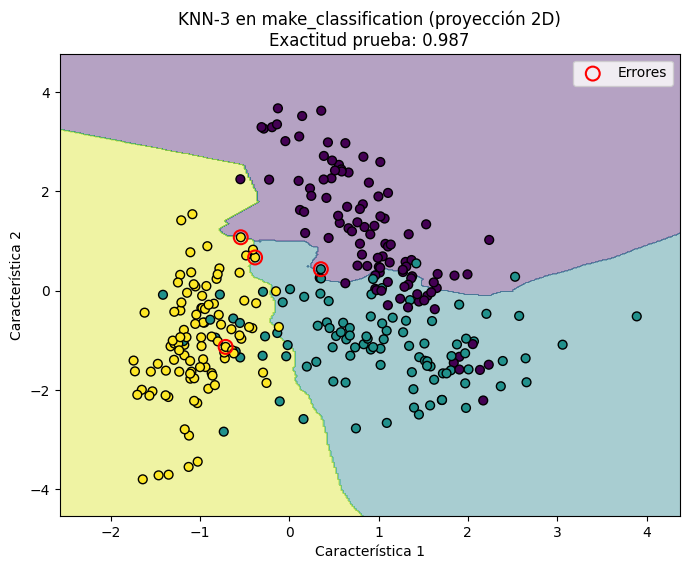

In [10]:
X, y = make_classification(n_samples=1000, n_features=3, n_informative=3, n_redundant=0,
                           n_repeated=0, n_classes=3, n_clusters_per_class=1, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, stratify=y, random_state=1000)

modelo = KNeighborsClassifier(n_neighbors=3)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Malla en las 2 primeras características; la tercera se fija a su media en train
media_tercera = X_train[:, 2].mean()
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
malla = np.c_[xx.ravel(), yy.ravel(), np.full(xx.ravel().shape, media_tercera)]
Z = modelo.predict(malla).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap='viridis')
scatter = plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='viridis', edgecolor='k', s=40)
errores = y_pred != y_test
plt.scatter(X_test[errores, 0], X_test[errores, 1], facecolors='none', edgecolors='red', 
            s=100, linewidths=1.5, label='Errores')
plt.title("KNN-3 en make_classification (proyección 2D)\nExactitud prueba: {:.3f}".format(accuracy_score(y_test, y_pred)))
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend()
plt.savefig('classification_knn3.png', dpi=150)
plt.show()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


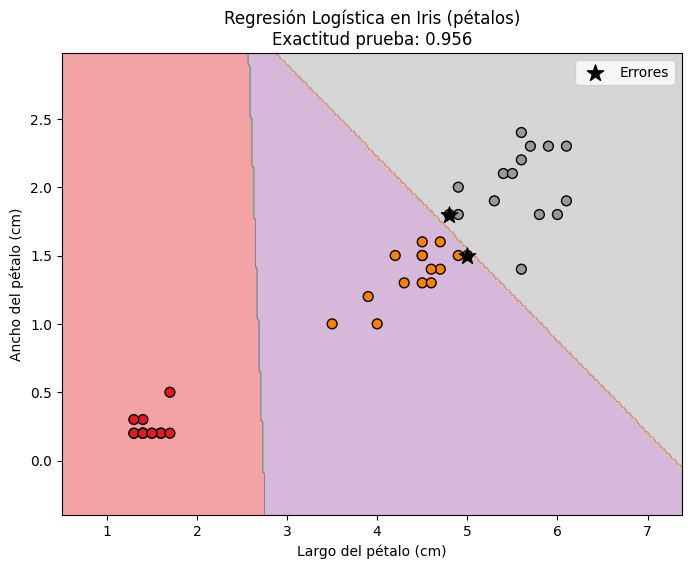

In [11]:
from sklearn.linear_model import LogisticRegression

X, y = load_iris(return_X_y=True)
# Usar solo características 2 y 3 (índices 2,3)
X2 = X[:, [2, 3]]
X_train, X_test, y_train, y_test = train_test_split(X2, y, train_size=0.7, stratify=y, random_state=1000)

modelo = LogisticRegression(max_iter=2500, solver='saga', multi_class='multinomial')
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Malla
x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap='Set1')
scatter = plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='Set1', edgecolor='k', s=50)
errores = y_pred != y_test
plt.scatter(X_test[errores, 0], X_test[errores, 1], marker='*', c='black', s=150, label='Errores')
plt.title("Regresión Logística en Iris (pétalos)\nExactitud prueba: {:.3f}".format(accuracy_score(y_test, y_pred)))
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.legend()
plt.savefig('iris_logreg.png', dpi=150)
plt.show()

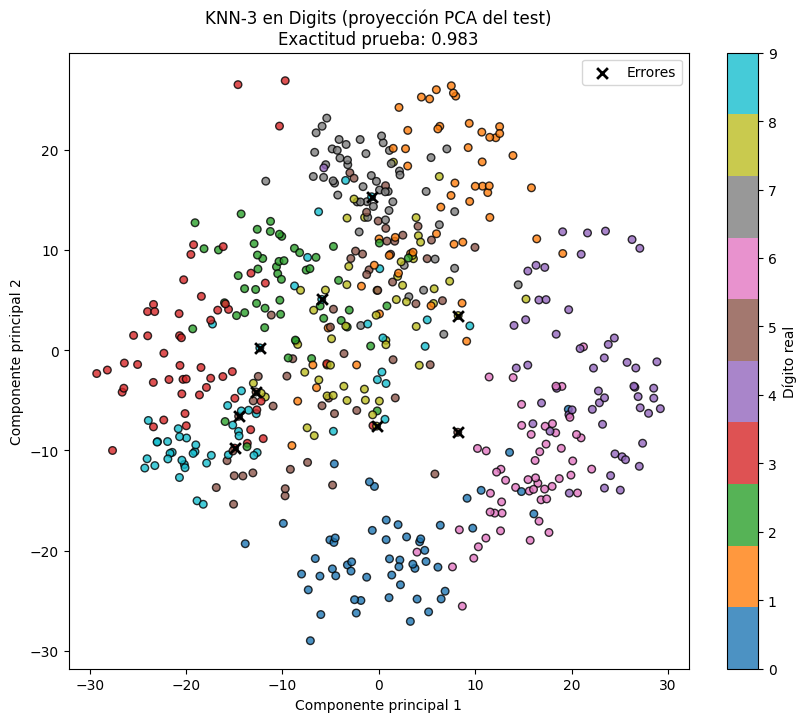

In [12]:
from sklearn.decomposition import PCA

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, stratify=y, random_state=1000)

modelo = KNeighborsClassifier(n_neighbors=3)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# PCA a 2 componentes sobre el conjunto de prueba (o sobre todo, para visualizar test)
pca = PCA(n_components=2)
pca.fit(X_train)  # ajustamos solo con train
X_test_pca = pca.transform(X_test)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='tab10', edgecolor='k', s=30, alpha=0.8)
errores = y_pred != y_test
plt.scatter(X_test_pca[errores, 0], X_test_pca[errores, 1], marker='x', c='black', s=60, linewidth=2, label='Errores')
plt.colorbar(scatter, ticks=range(10), label='Dígito real')
plt.title("KNN-3 en Digits (proyección PCA del test)\nExactitud prueba: {:.3f}".format(accuracy_score(y_test, y_pred)))
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.savefig('digits_knn3_pca.png', dpi=150)
plt.show()